# Scenarios and figures

Sensitivity scenarios and diagnostic figures built from the project clean data and within-product models.

In [7]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project_root_candidates = (Path.cwd(), *Path.cwd().parents)
project_root = next(
    (candidate for candidate in project_root_candidates if (candidate / "src" / "clean.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the project root from the current directory.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.clean import PRODUCT_CODE, load_clean, load_raw, match_cancelled_orders
from src.features import build_product_week
from src.models import fit_within_product

clean = load_clean(verbose=False)
figures_dir = project_root / "reports" / "figures"
tables_dir = project_root / "reports" / "tables"
figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)
print(f"Clean lines: {len(clean):,}; products: {clean['StockCode'].nunique():,}")

Clean lines: 524,894; products: 3,786


## Section 0 - Sanity check

Rebuild the customer-status samples as in notebook 05, then construct restricted E from eligible Sample E product-weeks as in notebook 04 Section 8.

In [8]:
partial_week_starts = pd.to_datetime(["2010-11-29", "2011-12-05"])

def build_eligible_weekly_sample(lines):
    weekly = build_product_week(lines)
    weekly = weekly.loc[~weekly["week"].isin(partial_week_starts)].copy()
    weekly["log_price"] = np.log(weekly["price_mode"])
    weekly["log_units"] = np.log(weekly["units"])
    weekly["log_invoices"] = np.log(weekly["invoices"])
    weekly["week_id"] = weekly["week"].astype(str)
    log_columns = ["log_price", "log_units", "log_invoices"]
    assert weekly[log_columns].notna().all().all()
    assert np.isfinite(weekly[log_columns].to_numpy()).all()

    eligibility = weekly.groupby("StockCode").agg(
        weeks=("week", "nunique"),
        distinct_prices=("price_mode", "nunique"),
    )
    eligible_products = eligibility.index[
        eligibility["weeks"].ge(10) & eligibility["distinct_prices"].ge(2)
    ]
    sample = weekly.loc[weekly["StockCode"].isin(eligible_products)].copy()
    assert sample.groupby("StockCode")["week"].nunique().ge(10).all()
    assert sample.groupby("StockCode")["price_mode"].nunique().ge(2).all()
    return sample

customer_groups = {
    "All": clean,
    "Identified": clean.loc[clean["CustomerID"].notna()].copy(),
    "Missing": clean.loc[clean["CustomerID"].isna()].copy(),
}
weekly_samples = {
    group_name: build_eligible_weekly_sample(group_data)
    for group_name, group_data in customer_groups.items()
}

all_product_week = build_product_week(clean)
mode_observations = clean.merge(
    all_product_week[["StockCode", "week", "price_mode"]],
    on=["StockCode", "week"],
    how="left",
    validate="many_to_one",
)
mode_counts = (
    mode_observations.loc[mode_observations["UnitPrice"].eq(mode_observations["price_mode"])]
    .groupby(["StockCode", "week"])
    .agg(mode_lines=("UnitPrice", "size"), mode_units=("Quantity", "sum"))
    .reset_index()
)
line_counts = clean.groupby(["StockCode", "week"]).size().rename("lines").reset_index()
weekly_diagnostics = all_product_week.merge(
    line_counts, on=["StockCode", "week"], how="left", validate="one_to_one"
).merge(
    mode_counts, on=["StockCode", "week"], how="left", validate="one_to_one"
)
weekly_diagnostics["mode_share_lines"] = weekly_diagnostics["mode_lines"] / weekly_diagnostics["lines"]
weekly_diagnostics["mode_share_units"] = weekly_diagnostics["mode_units"] / weekly_diagnostics["units"]
weekly_diagnostics = weekly_diagnostics.loc[
    ~weekly_diagnostics["week"].isin(partial_week_starts)
].copy()
weekly_diagnostics["log_price"] = np.log(weekly_diagnostics["price_mode"])
weekly_diagnostics["log_units"] = np.log(weekly_diagnostics["units"])
weekly_diagnostics["log_invoices"] = np.log(weekly_diagnostics["invoices"])
weekly_diagnostics["week_id"] = weekly_diagnostics["week"].astype(str)
sample_e = weekly_diagnostics.loc[weekly_diagnostics["StockCode"].isin(weekly_samples["All"]["StockCode"].unique())].copy()
sample_e = sample_e.merge(
    weekly_samples["All"][["StockCode", "week"]],
    on=["StockCode", "week"],
    how="inner",
    validate="one_to_one",
)
assert len(sample_e) == len(weekly_samples["All"])
restricted_e = sample_e.loc[sample_e["mode_share_units"].ge(0.9)].copy()

model_fits = {}
def get_fit(key, data, outcome):
    if key not in model_fits:
        model_fits[key] = fit_within_product(data, outcome)
    return model_fits[key]

sanity_rows = []
for group_name, sample in weekly_samples.items():
    for outcome in ("log_invoices", "log_units"):
        fitted = get_fit((group_name, outcome), sample, outcome)
        ci_lower, ci_upper = fitted.conf_int().loc["log_price"]
        sanity_rows.append({
            "group": group_name,
            "outcome": outcome,
            "coefficient": fitted.params["log_price"],
            "ci_lower": ci_lower,
            "ci_upper": ci_upper,
            "observations": int(fitted.nobs),
            "products": sample["StockCode"].nunique(),
        })
sanity_results = pd.DataFrame(sanity_rows)
expected_invoice_coefficients = {"All": -0.397409, "Identified": -0.493074, "Missing": -0.494630}
for group_name, expected in expected_invoice_coefficients.items():
    estimate = sanity_results.loc[
        sanity_results["group"].eq(group_name) & sanity_results["outcome"].eq("log_invoices"),
        "coefficient",
    ].iloc[0]
    assert abs(estimate - expected) < 1e-6, (group_name, estimate, expected)

identified_fit = get_fit(("Identified", "log_invoices"), weekly_samples["Identified"], "log_invoices")
restricted_fit = get_fit(("restricted E", "log_invoices"), restricted_e, "log_invoices")
identified_count = int(identified_fit.nobs)
restricted_count = int(restricted_fit.nobs)
assert identified_count != restricted_count
identified_coefficient = identified_fit.params["log_price"]
restricted_coefficient = restricted_fit.params["log_price"]
identified_products = weekly_samples["Identified"]["StockCode"].nunique()
restricted_products = restricted_e["StockCode"].nunique()
print("Identified vs restricted E (log_invoices):")
print(f"Identified: observations={identified_count:,}, products={identified_products:,}, coefficient={identified_coefficient:.9f}")
print(f"Restricted E: observations={restricted_count:,}, products={restricted_products:,}, coefficient={restricted_coefficient:.9f}")
print(f"Six-decimal agreement: {round(identified_coefficient, 6) == round(restricted_coefficient, 6)}")
print("The near-match to five decimal places is a coincidence between different samples; neither sample is adjusted.")
print("Sanity coefficients (log_invoices):")
print(sanity_results.loc[
    sanity_results["outcome"].eq("log_invoices"),
    ["group", "observations", "products", "coefficient", "ci_lower", "ci_upper"],
].to_string(index=False, formatters={"coefficient": "{:.9f}".format}))

Identified vs restricted E (log_invoices):
Identified: observations=50,237, products=1,597, coefficient=-0.493074032
Restricted E: observations=56,298, products=2,518, coefficient=-0.493070681
Six-decimal agreement: False
The near-match to five decimal places is a coincidence between different samples; neither sample is adjusted.
Sanity coefficients (log_invoices):
     group  observations  products  coefficient  ci_lower  ci_upper
       All         83377      2523 -0.397408759 -0.425223 -0.369594
Identified         50237      1597 -0.493074032 -0.540648 -0.445500
   Missing         45449      1851 -0.494629738 -0.537857 -0.451403


## Section 1 - Scenario table

Each baseline is clean line value for products eligible in that group. Elasticities and confidence limits are refit from the eligible weekly samples.

In [9]:
price_changes = [-0.10, -0.05, 0.05, 0.10]
scenario_rows = []
for group_name, sample in weekly_samples.items():
    eligible_codes = sample["StockCode"].unique()
    baseline_line_value = clean.loc[clean["StockCode"].isin(eligible_codes), "line_value"].sum()
    for elasticity_case, outcome in (("conservative", "log_invoices"), ("upper bound", "log_units")):
        fitted = get_fit((group_name, outcome), sample, outcome)
        ci_lower, ci_upper = fitted.conf_int().loc["log_price"]
        elasticity_values = (("point", fitted.params["log_price"]), ("95% CI lower", ci_lower), ("95% CI upper", ci_upper))
        for price_change in price_changes:
            for case_label, elasticity in elasticity_values:
                quantity_multiplier = (1 + price_change) ** elasticity
                line_value_multiplier = (1 + price_change) ** (1 + elasticity)
                scenario_rows.append({
                    "group": group_name,
                    "outcome": outcome,
                    "price_change": price_change,
                    "elasticity_case": elasticity_case,
                    "elasticity": elasticity,
                    "quantity_change_pct": (quantity_multiplier - 1) * 100,
                    "line_value_change_pct": (line_value_multiplier - 1) * 100,
                    "baseline_line_value": baseline_line_value,
                    "line_value_change_abs": baseline_line_value * (line_value_multiplier - 1),
                })
scenario_table = pd.DataFrame(scenario_rows)
scenario_table = scenario_table[[
    "group", "outcome", "price_change", "elasticity_case", "elasticity",
    "quantity_change_pct", "line_value_change_pct", "baseline_line_value",
    "line_value_change_abs",
]]
scenario_csv = tables_dir / "scenario_table.csv"
scenario_table.to_csv(scenario_csv, index=False)

identified_bulk_lines = clean.loc[clean["CustomerID"].notna() & clean["Quantity"].ge(24)].copy()
identified_bulk_lines["product_median_price"] = identified_bulk_lines["StockCode"].map(clean.groupby("StockCode")["UnitPrice"].median())
bulk_below_median_share = identified_bulk_lines["UnitPrice"].lt(identified_bulk_lines["product_median_price"]).mean()
assert abs(bulk_below_median_share - 0.347) < 0.001
print(f"Identified lines with Quantity >= 24 priced below product median: {bulk_below_median_share:.1%}")
print(f"Saved: {scenario_csv.relative_to(project_root)}")
print(scenario_table.to_string(index=False, formatters={"elasticity": "{:.6f}".format, "quantity_change_pct": "{:.3f}".format, "line_value_change_pct": "{:.3f}".format, "baseline_line_value": "{:.2f}".format, "line_value_change_abs": "{:.2f}".format}))

Identified lines with Quantity >= 24 priced below product median: 34.7%
Saved: reports\tables\scenario_table.csv
     group      outcome  price_change elasticity_case elasticity quantity_change_pct line_value_change_pct baseline_line_value line_value_change_abs
       All log_invoices         -0.10    conservative  -0.397409               4.276                -6.152          7766695.95            -477774.99
       All log_invoices         -0.10    conservative  -0.425223               4.582                -5.876          7766695.95            -456383.19
       All log_invoices         -0.10    conservative  -0.369594               3.971                -6.426          7766695.95            -499104.19
       All log_invoices         -0.05    conservative  -0.397409               2.059                -3.044          7766695.95            -236387.89
       All log_invoices         -0.05    conservative  -0.425223               2.205                -2.905          7766695.95            -225

This is a scenario sensitivity, not an optimization. The estimates are associations, not causal effects. Line value is price x quantity, not revenue or profit, and the data contain no cost information. Units elasticity is likely overstated because large orders carry lower prices (34.7% of identified lines with Quantity >= 24 are priced below the product median). Invoice and units bounds point in opposite directions, so the data do not support a price-direction recommendation.

## Section 2 - Figures

All figures are saved at 150 dpi and displayed inline.

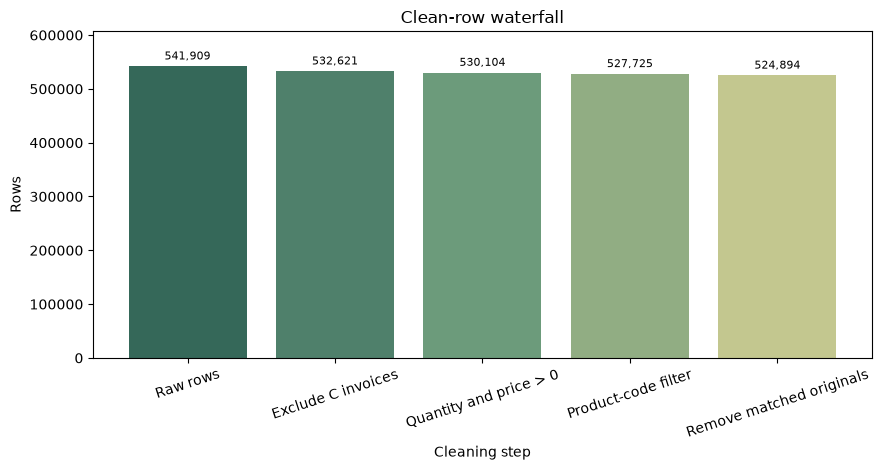

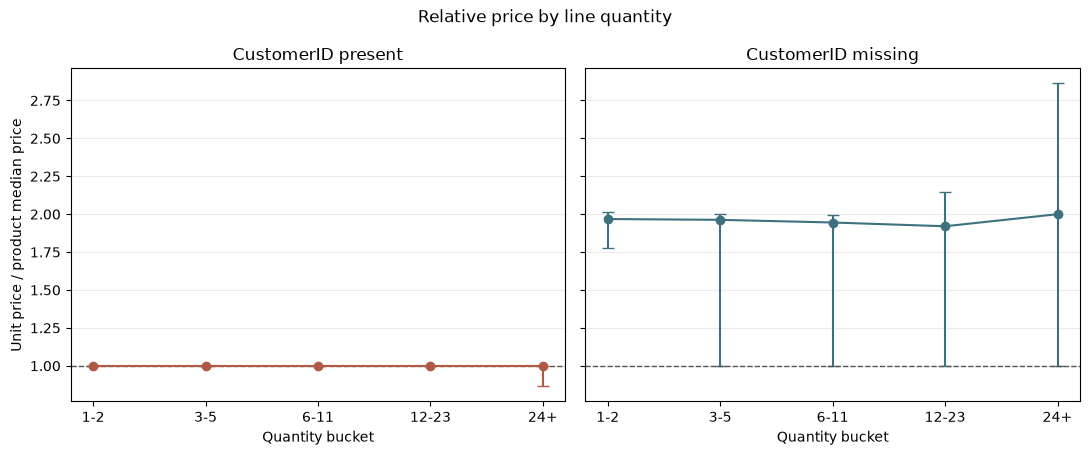

In [11]:
raw = load_raw()
waterfall_frames = [raw]
not_cancelled = raw.loc[~raw["InvoiceNo"].astype(str).str.startswith("C")]
waterfall_frames.append(not_cancelled)
positive_priced = not_cancelled.loc[not_cancelled["Quantity"].gt(0) & not_cancelled["UnitPrice"].gt(0)]
waterfall_frames.append(positive_priced)
product_codes = positive_priced.loc[positive_priced["StockCode"].str.match(PRODUCT_CODE)]
waterfall_frames.append(product_codes)
matched_positive, _ = match_cancelled_orders(raw)
after_matched_cancellations = product_codes.loc[~product_codes.index.isin(matched_positive)]
waterfall_frames.append(after_matched_cancellations)
waterfall_counts = [len(frame) for frame in waterfall_frames]
expected_waterfall_counts = [541_909, 532_621, 530_104, 527_725, 524_894]
assert waterfall_counts == expected_waterfall_counts, waterfall_counts
assert waterfall_counts[-1] == len(load_clean(verbose=False)) == len(clean)

fig1, ax = plt.subplots(figsize=(9, 4.8))
step_labels = ["Raw rows", "Exclude C invoices", "Quantity and price > 0", "Product-code filter", "Remove matched originals"]
bars = ax.bar(step_labels, waterfall_counts, color=["#356859", "#4f806b", "#6c9b7b", "#91ad83", "#c3c78f"])
ax.set_title("Clean-row waterfall")
ax.set_ylabel("Rows")
ax.set_xlabel("Cleaning step")
ax.tick_params(axis="x", rotation=18)
ax.set_ylim(0, max(waterfall_counts) * 1.12)
ax.bar_label(bars, labels=[f"{count:,}" for count in waterfall_counts], padding=3, fontsize=8)
fig1.tight_layout()
fig1.savefig(figures_dir / "fig1_cleaning_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()

product_line_counts = clean.groupby("StockCode").size()
qualifying_products = product_line_counts.index[product_line_counts.ge(20)]
product_median_price = clean.groupby("StockCode")["UnitPrice"].transform("median")
ratio_lines = clean.assign(price_ratio=clean["UnitPrice"] / product_median_price)
ratio_lines = ratio_lines.loc[ratio_lines["StockCode"].isin(qualifying_products)].copy()
quantity_bucket_labels = ["1-2", "3-5", "6-11", "12-23", "24+"]
ratio_lines["quantity_bucket"] = pd.cut(ratio_lines["Quantity"], bins=[0, 2, 5, 11, 23, np.inf], labels=quantity_bucket_labels, right=True)
fig2, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for axis, customer_present, panel_title in zip(axes, (True, False), ("CustomerID present", "CustomerID missing")):
    cohort = ratio_lines.loc[ratio_lines["CustomerID"].notna() if customer_present else ratio_lines["CustomerID"].isna()]
    summary = cohort.groupby("quantity_bucket", observed=False)["price_ratio"].agg(
        median="median", p25=lambda values: values.quantile(0.25), p75=lambda values: values.quantile(0.75)
    ).reindex(quantity_bucket_labels)
    x = np.arange(len(quantity_bucket_labels))
    y = summary["median"].to_numpy()
    yerr = np.vstack([y - summary["p25"].to_numpy(), summary["p75"].to_numpy() - y])
    axis.errorbar(x, y, yerr=yerr, fmt="o-", capsize=4, color="#b05a45" if customer_present else "#3d7180")
    axis.axhline(1, color="#555555", linewidth=1, linestyle="--")
    axis.set_xticks(x, quantity_bucket_labels)
    axis.set_title(panel_title)
    axis.set_xlabel("Quantity bucket")
    axis.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Unit price / product median price")
fig2.suptitle("Relative price by line quantity")
fig2.tight_layout()
fig2.savefig(figures_dir / "fig2_price_ratio_by_quantity.png", dpi=150, bbox_inches="tight")
plt.show()

Coefficient estimates used in Figure 3:
                     sample      outcome coefficient  ci_lower  ci_upper  observations  products
                          E log_invoices   -0.397409 -0.425223 -0.369594         83377      2523
                          E    log_units   -1.502479 -1.550792 -1.454167         83377      2523
E (mode_share_units >= 0.9) log_invoices   -0.493071 -0.524442 -0.461700         56298      2518
E (mode_share_units >= 0.9)    log_units   -1.841976 -1.901949 -1.782003         56298      2518
                          B log_invoices   -0.332338 -0.420234 -0.244443          5533       348
                          B    log_units   -1.497819 -1.645293 -1.350345          5533       348
                 Identified log_invoices   -0.493074 -0.540648 -0.445500         50237      1597
                 Identified    log_units   -1.703228 -1.782013 -1.624443         50237      1597
                    Missing log_invoices   -0.494630 -0.537857 -0.451403         45449 

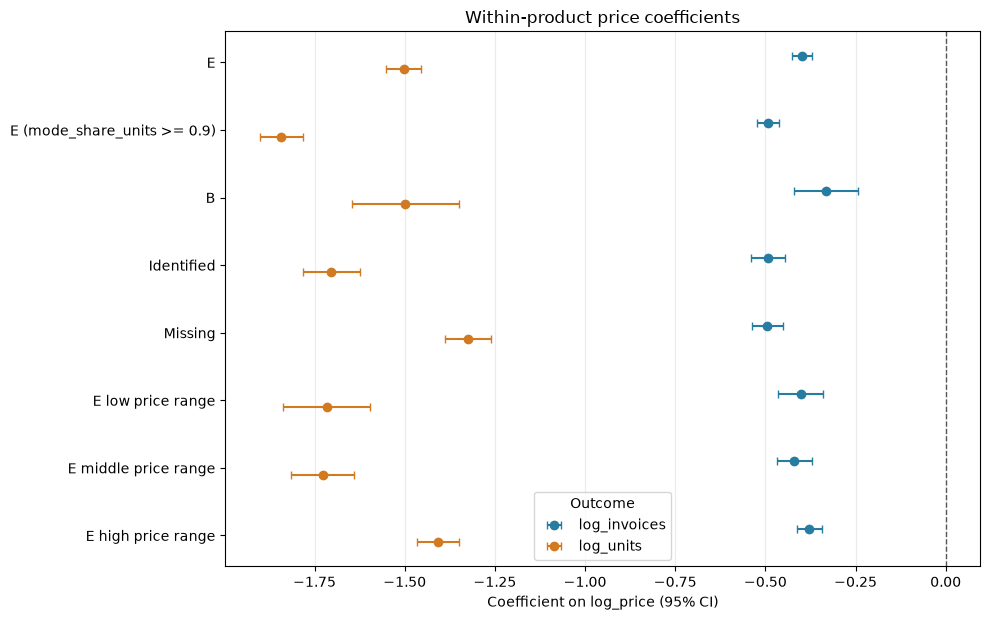

In [12]:
sample_b_base = weekly_diagnostics.loc[
    weekly_diagnostics["invoices"].ge(3) & weekly_diagnostics["mode_share_lines"].ge(0.8)
].copy()
b_eligibility = sample_b_base.groupby("StockCode").agg(weeks=("week", "nunique"), distinct_prices=("price_mode", "nunique"))
b_products = b_eligibility.index[b_eligibility["weeks"].ge(10) & b_eligibility["distinct_prices"].ge(2)]
sample_b = sample_b_base.loc[sample_b_base["StockCode"].isin(b_products)].copy()

e_product_price_ratio = sample_e.groupby("StockCode")["price_mode"].agg(lambda prices: prices.max() / prices.min())
e_ratio_groups, e_ratio_bins = pd.qcut(e_product_price_ratio, q=3, labels=["low", "middle", "high"], retbins=True)
sample_e_terciles = sample_e.copy()
sample_e_terciles["price_ratio_group"] = sample_e_terciles["StockCode"].map(e_ratio_groups)
assert sample_e_terciles["price_ratio_group"].notna().all()

coefficient_samples = {
    "E": sample_e,
    "E (mode_share_units >= 0.9)": restricted_e,
    "B": sample_b,
    "Identified": weekly_samples["Identified"],
    "Missing": weekly_samples["Missing"],
}
for tercile in ("low", "middle", "high"):
    coefficient_samples[f"E {tercile} price range"] = sample_e_terciles.loc[sample_e_terciles["price_ratio_group"].eq(tercile)].copy()

coefficient_rows = []
for sample_name, sample in coefficient_samples.items():
    for outcome in ("log_invoices", "log_units"):
        fit_key = (sample_name, outcome)
        fitted = get_fit(fit_key, sample, outcome)
        ci_lower, ci_upper = fitted.conf_int().loc["log_price"]
        coefficient_rows.append({"sample": sample_name, "outcome": outcome, "coefficient": fitted.params["log_price"], "ci_lower": ci_lower, "ci_upper": ci_upper, "observations": int(fitted.nobs), "products": sample["StockCode"].nunique()})
coefficient_results = pd.DataFrame(coefficient_rows)
e_invoice_estimate = coefficient_results.loc[coefficient_results["sample"].eq("E") & coefficient_results["outcome"].eq("log_invoices"), "coefficient"].iloc[0]
assert abs(e_invoice_estimate - (-0.397409)) < 1e-6
print("Coefficient estimates used in Figure 3:")
print(coefficient_results.to_string(index=False, formatters={"coefficient": "{:.6f}".format, "ci_lower": "{:.6f}".format, "ci_upper": "{:.6f}".format}))

sample_order = list(coefficient_samples)
y_positions = np.arange(len(sample_order))
fig3, ax = plt.subplots(figsize=(10, 6.3))
outcome_styles = {"log_invoices": ("#277da1", -0.10, "log_invoices"), "log_units": ("#d17a22", 0.10, "log_units")}
for outcome, (color, offset, legend_label) in outcome_styles.items():
    rows = coefficient_results.loc[coefficient_results["outcome"].eq(outcome)].set_index("sample").loc[sample_order]
    points = rows["coefficient"].to_numpy()
    lower = rows["ci_lower"].to_numpy()
    upper = rows["ci_upper"].to_numpy()
    ax.errorbar(points, y_positions + offset, xerr=np.vstack([points - lower, upper - points]), fmt="o", capsize=3, color=color, label=legend_label)
ax.axvline(0, color="#555555", linewidth=1, linestyle="--")
ax.set_yticks(y_positions, sample_order)
ax.invert_yaxis()
ax.set_xlabel("Coefficient on log_price (95% CI)")
ax.set_title("Within-product price coefficients")
ax.legend(title="Outcome")
ax.grid(axis="x", alpha=0.25)
fig3.tight_layout()
fig3.savefig(figures_dir / "fig3_coefficient_plot.png", dpi=150, bbox_inches="tight")
plt.show()

Most negative eligible Sample E log_units Spearman product: 22887, r=-0.999435


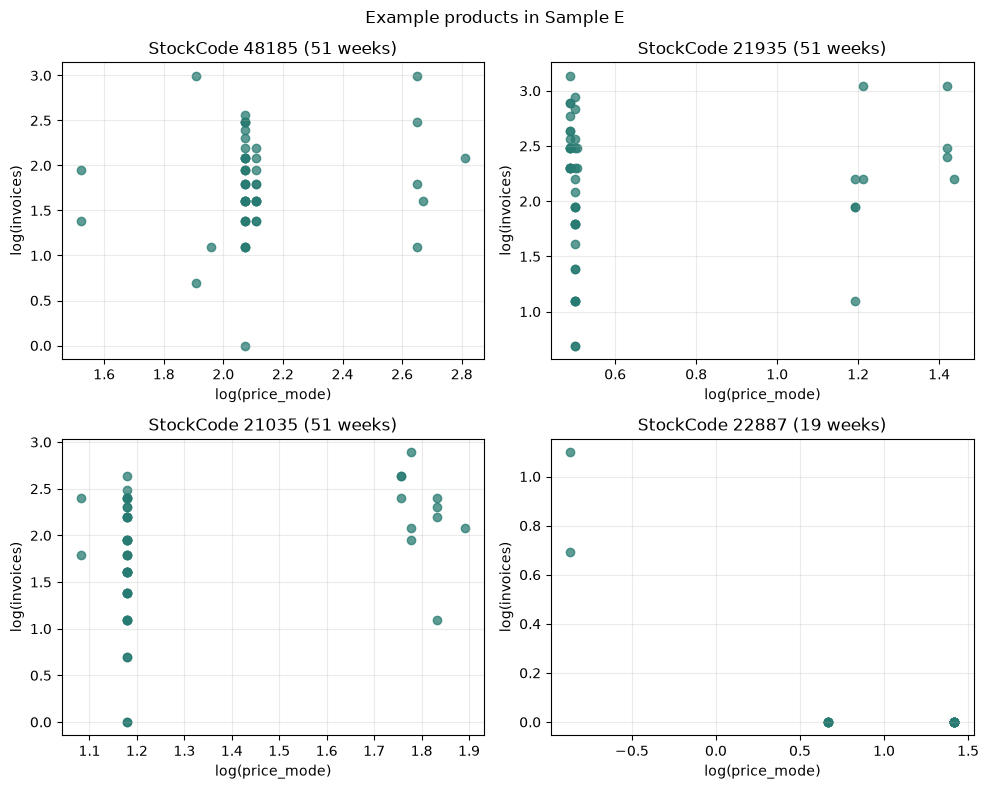

In [13]:
example_codes = ["48185", "21935", "21035"]
available_codes = set(sample_e["StockCode"].astype(str))
assert set(example_codes).issubset(available_codes)
negative_correlations = {}
for stock_code, product_rows in sample_e.groupby("StockCode", sort=False):
    if product_rows["price_mode"].nunique() >= 3 and product_rows["units"].nunique() > 1:
        negative_correlations[stock_code] = np.log(product_rows["price_mode"]).rank().corr(np.log(product_rows["units"]).rank())
negative_correlations = pd.Series(negative_correlations).dropna().sort_values()
negative_candidates = negative_correlations.loc[~negative_correlations.index.astype(str).isin(example_codes)]
assert not negative_candidates.empty
most_negative_code = str(negative_candidates.index[0])
example_codes.append(most_negative_code)
print(f"Most negative eligible Sample E log_units Spearman product: {most_negative_code}, r={negative_candidates.iloc[0]:.6f}")

fig4, axes = plt.subplots(2, 2, figsize=(10, 8))
for axis, stock_code in zip(axes.flat, example_codes):
    product_rows = sample_e.loc[sample_e["StockCode"].astype(str).eq(stock_code)].sort_values("week")
    assert product_rows["week"].is_unique
    assert product_rows["price_mode"].gt(0).all() and product_rows["invoices"].gt(0).all()
    axis.scatter(np.log(product_rows["price_mode"]), np.log(product_rows["invoices"]), alpha=0.75, color="#287b72")
    axis.set_title(f"StockCode {stock_code} ({len(product_rows)} weeks)")
    axis.set_xlabel("log(price_mode)")
    axis.set_ylabel("log(invoices)")
    axis.grid(alpha=0.25)
fig4.suptitle("Example products in Sample E")
fig4.tight_layout()
fig4.savefig(figures_dir / "fig4_example_products.png", dpi=150, bbox_inches="tight")
plt.show()

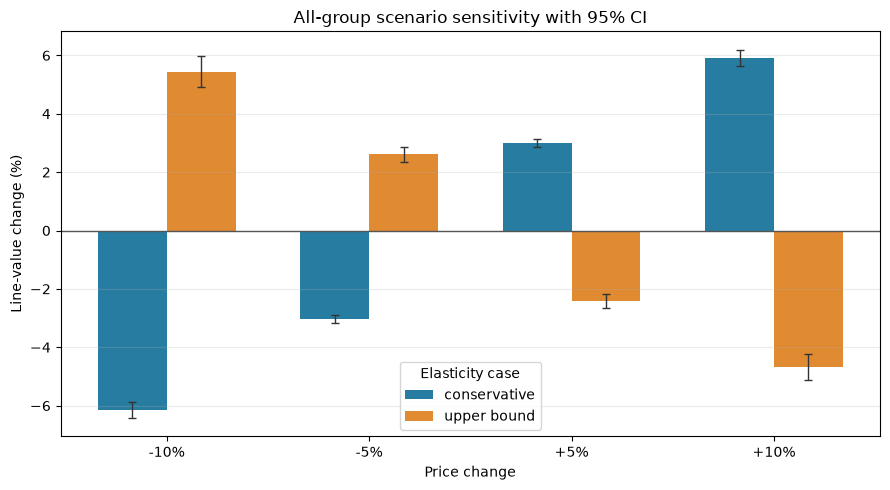

Created files:
reports\tables\scenario_table.csv
reports\figures\fig1_cleaning_waterfall.png
reports\figures\fig2_price_ratio_by_quantity.png
reports\figures\fig3_coefficient_plot.png
reports\figures\fig4_example_products.png
reports\figures\fig5_scenarios.png


In [14]:
all_scenarios = scenario_table.loc[scenario_table["group"].eq("All")].copy()
figure5_changes = price_changes
x = np.arange(len(figure5_changes))
bar_width = 0.34
fig5, ax = plt.subplots(figsize=(9, 5))
case_colors = {"conservative": "#277da1", "upper bound": "#e08a32"}
for case_index, elasticity_case in enumerate(("conservative", "upper bound")):
    outcome = "log_invoices" if elasticity_case == "conservative" else "log_units"
    fitted = get_fit(("All", outcome), weekly_samples["All"], outcome)
    ci_lower, ci_upper = fitted.conf_int().loc["log_price"]
    points = []
    errors = []
    for price_change in figure5_changes:
        price_subset = all_scenarios.loc[
            all_scenarios["price_change"].eq(price_change)
            & all_scenarios["elasticity_case"].eq(elasticity_case)
        ]
        point_row = price_subset.loc[
            np.isclose(price_subset["elasticity"], fitted.params["log_price"])
        ].iloc[0]
        point = point_row["line_value_change_pct"]
        points.append(point)
        transformed = [(1 + price_change) ** (1 + value) - 1 for value in (ci_lower, ci_upper)]
        low_pct, high_pct = min(transformed) * 100, max(transformed) * 100
        errors.append([point - low_pct, high_pct - point])
    errors = np.asarray(errors).T
    positions = x + (case_index - 0.5) * bar_width
    ax.bar(positions, points, width=bar_width, color=case_colors[elasticity_case], label=elasticity_case)
    ax.errorbar(positions, points, yerr=errors, fmt="none", ecolor="#333333", capsize=3, linewidth=1)
ax.axhline(0, color="#555555", linewidth=1)
ax.set_xticks(x, [f"{change:+.0%}" for change in figure5_changes])
ax.set_xlabel("Price change")
ax.set_ylabel("Line-value change (%)")
ax.set_title("All-group scenario sensitivity with 95% CI")
ax.legend(title="Elasticity case")
ax.grid(axis="y", alpha=0.25)
fig5.tight_layout()
fig5.savefig(figures_dir / "fig5_scenarios.png", dpi=150, bbox_inches="tight")
plt.show()

created_files = [scenario_csv] + [figures_dir / f"fig{number}_{suffix}.png" for number, suffix in ((1, "cleaning_waterfall"), (2, "price_ratio_by_quantity"), (3, "coefficient_plot"), (4, "example_products"), (5, "scenarios"))]
print("Created files:")
for output_path in created_files:
    assert output_path.is_file()
    print(output_path.relative_to(project_root))